# Previsão de consumo de energia

Objetivo: prever o consumo elétrico dos aparelhos (`Appliances`) e comparar
diferentes modelos com um baseline simples.

Os dados são de uma única residência, com medições a cada 10 minutos
durante cerca de 4,5 meses.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../data/energydata_complete.csv", parse_dates=["date"])
df["hora"] = df["date"].dt.hour
df["fim_de_semana"] = (df["date"].dt.day_of_week >= 5).astype(int)

print(df.shape)
df.head()

(19735, 31)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,hora,fim_de_semana
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,17,0
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,17,0
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,17,0
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389,17,0
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,17,0


In [2]:
def avaliar(nome, y_true, y_pred):
    """Calcula as três métricas de uma vez e devolve um dicionário."""
    return {
        "modelo": nome,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

---
## Tentativa 1: usando apenas clima e horário

Primeiro vou tentar prever o consumo usando só as variáveis que já tenho:
temperatura, umidade, vento, hora do dia e tipo de dia.

**Divisão treino/teste:** como estes dados são uma série temporal, não embaralho
os dados. Treino nos 80% iniciais (passado) e testo nos 20% finais (futuro),
como seria na vida real.

In [3]:
features = ["T_out", "RH_out", "Windspeed", "T1", "RH_1", "hora", "fim_de_semana"]
X = df[features]
y = df["Appliances"]

corte = int(len(df) * 0.8)
X_train, X_test = X.iloc[:corte], X.iloc[corte:]
y_train, y_test = y.iloc[:corte], y.iloc[corte:]

print("Treino:", len(X_train), "| Teste:", len(X_test))

Treino: 15788 | Teste: 3947


### Baseline

Antes de qualquer modelo, preciso de um ponto de comparação. O baseline
"prevê" sempre a média do treino. Todo modelo precisa ganhar dele,
senão não está agregando nada.

In [4]:
y_base = np.full(len(y_test), y_train.mean())
print("MAE baseline:", mean_absolute_error(y_test, y_base))

MAE baseline: 52.684938078385834


In [5]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"MAE: {mae:.1f} | RMSE: {rmse:.1f} | R²: {r2:.3f}")

MAE: 53.6 | RMSE: 88.6 | R²: 0.052


In [6]:
coeficientes = pd.Series(modelo.coef_, index=features).sort_values()
print(coeficientes)

T_out           -2.555603
RH_out          -1.394920
Windspeed        0.701048
fim_de_semana    1.822170
hora             2.670342
T1               3.483304
RH_1             4.634992
dtype: float64


Cada coeficiente mostra quanto o consumo muda ao aumentar a variável em 1 unidade,
mantendo as outras fixas. Como as escalas são diferentes (°C, %, km/h),
a comparação entre eles serve só como leitura qualitativa.

R² RF: -1.8905145932721563


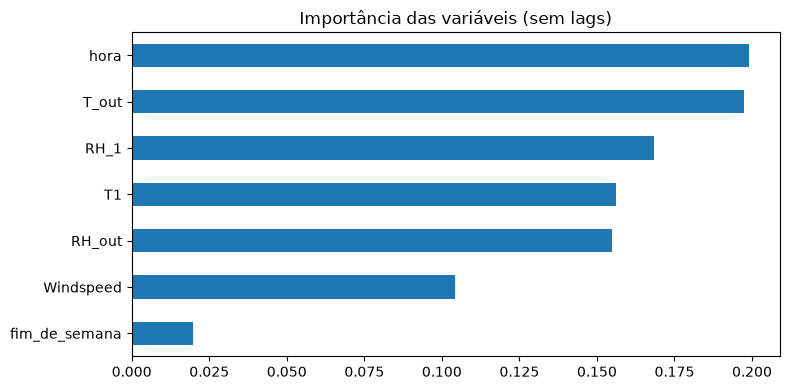

In [7]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=2)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print("R² RF:", r2_score(y_test, y_pred_rf))

importancias = pd.Series(rf.feature_importances_, index=features).sort_values()
importancias.plot(kind="barh", figsize=(8, 4),
                  title="Importância das variáveis (sem lags)")
plt.tight_layout()
plt.show()

In [8]:
resultados_v1 = pd.DataFrame([
    avaliar("Baseline (média)", y_test, y_base),
    avaliar("Regressão linear", y_test, y_pred),
    avaliar("Random Forest", y_test, y_pred_rf),
])
resultados_v1.round(3)

,modelo,MAE,RMSE,R2
0,Baseline (média),52.685,91.053,-0.000
1,Regressão linear,53.636,88.641,0.052
2,Random Forest,112.660,154.779,-1.891


### Resultado da tentativa 1

Usando apenas clima e horário, nenhum modelo superou o baseline:
a regressão linear teve R² de 0,052 e o Random Forest teve R² negativo (-1,89),
ou seja, ficou **pior do que simplesmente prever a média**.

O R² negativo indica overfitting: como os dados cobrem de janeiro a maio,
o período de teste tem temperaturas que não aparecem no treino, e o
Random Forest não consegue extrapolar para faixas que nunca viu.

**Conclusão:** o clima explica muito pouco do consumo. Na próxima etapa vou
incluir o histórico recente de consumo (lag features), que costuma ser o
fator mais forte em séries temporais.

---
## Tentativa 2: incluindo o histórico recente

Agora vou criar variáveis novas:

- **lag_1**: consumo de 10 minutos atrás
- **lag_6**: consumo de 1 hora atrás
- **lag_144**: consumo de 24 horas atrás
- **media_1h**: média das últimas 6 medições
- **hora_sin / hora_cos**: a hora representada como um ciclo, para o modelo
  entender que 23h e 0h são vizinhas

O `shift(1)` antes do `rolling` é essencial: garante que só uso informação
do passado. Usar o valor do próprio instante seria colar na prova
(o chamado *data leakage*).

In [9]:
df = df.sort_values("date").reset_index(drop=True)

df["lag_1"]    = df["Appliances"].shift(1)
df["lag_6"]    = df["Appliances"].shift(6)
df["lag_144"]  = df["Appliances"].shift(144)
df["media_1h"] = df["Appliances"].shift(1).rolling(6).mean()

df["hora_sin"] = np.sin(2 * np.pi * df["hora"] / 24)
df["hora_cos"] = np.cos(2 * np.pi * df["hora"] / 24)

df = df.dropna().reset_index(drop=True)

print(df.shape)
df[["date", "Appliances", "lag_1", "lag_6", "lag_144", "media_1h"]].head()

(19591, 37)


,date,Appliances,lag_1,lag_6,lag_144,media_1h
0,2016-01-12 17:00:00,60,40.0,30.0,60.0,40.000000
1,2016-01-12 17:10:00,60,60.0,40.0,60.0,45.000000
2,2016-01-12 17:20:00,210,60.0,50.0,50.0,48.333333
3,2016-01-12 17:30:00,380,210.0,40.0,50.0,75.000000
4,2016-01-12 17:40:00,370,380.0,40.0,60.0,131.666667


In [10]:
features = ["lag_1", "lag_6", "lag_144", "media_1h",
            "hora_sin", "hora_cos", "fim_de_semana",
            "T_out", "RH_out", "T1", "RH_1"]

X, y = df[features], df["Appliances"]
corte = int(len(df) * 0.8)
X_train, X_test = X.iloc[:corte], X.iloc[corte:]
y_train, y_test = y.iloc[:corte], y.iloc[corte:]

print("Treino:", len(X_train), "| Teste:", len(X_test))

Treino: 15672 | Teste: 3919


In [11]:
# Baseline
y_base = np.full(len(y_test), y_train.mean())

# Regressão linear
modelo = LinearRegression()
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

# Random Forest com limites para evitar overfitting
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=2,
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print(len(y_test), len(y_base), len(y_pred), len(y_pred_rf))

3919 3919 3919 3919


In [12]:
resultados_v2 = pd.DataFrame([
    avaliar("Baseline (média)", y_test, y_base),
    avaliar("Regressão linear", y_test, y_pred),
    avaliar("Random Forest", y_test, y_pred_rf),
])
resultados_v2.round(3)

,modelo,MAE,RMSE,R2
0,Baseline (média),51.599,87.899,-0.002
1,Regressão linear,26.504,59.739,0.537
2,Random Forest,27.659,59.531,0.541


### Resultado da tentativa 2

Incluir o consumo passado melhorou muito os modelos:

| Modelo | MAE (Wh) | RMSE (Wh) | R² |
|---|---|---|---|
| Baseline (média) | 51,6 | 87,9 | -0,002 |
| Regressão linear | 26,5 | 59,7 | 0,537 |
| Random Forest | 27,7 | 59,5 | 0,541 |

O erro médio caiu pela metade em relação à tentativa 1, e o R² passou de
negativo para cerca de 0,54.

Pontos de destaque:

- A **regressão linear teve desempenho praticamente igual** ao do Random Forest,
  apesar de ser muito mais simples e rápida. Em produção, ela seria a escolha sensata.
- A diferença entre MAE (26,5) e RMSE (59,7) mostra que o modelo acerta o
  consumo normal, mas erra bastante nos picos. O RMSE pune mais os erros grandes.
- O que mais ajudou foi o **histórico recente**, não o clima.

**Importante:** com lag features, o modelo prevê o consumo dos **próximos 10 minutos**,
e não o de dias à frente. São problemas diferentes.

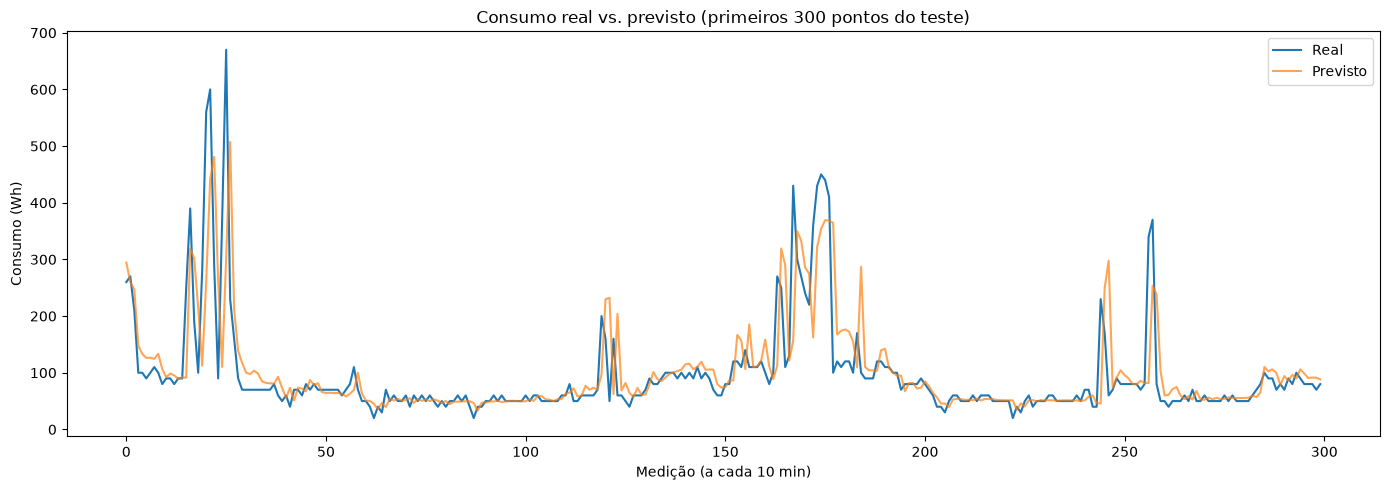

In [13]:
plt.figure(figsize=(14, 5))
plt.plot(y_test.values[:300], label="Real")
plt.plot(y_pred_rf[:300], label="Previsto", alpha=0.7)
plt.title("Consumo real vs. previsto (primeiros 300 pontos do teste)")
plt.xlabel("Medição (a cada 10 min)")
plt.ylabel("Consumo (Wh)")
plt.legend()
plt.tight_layout()
plt.savefig("../images/real_vs_previsto.png", dpi=150)
plt.show()

### O que o gráfico mostra

O modelo acompanha bem o consumo de base (faixa de 50 a 100 Wh),
mas falha nos picos:

- **Não alcança os picos reais.** Em picos de 600 a 670 Wh, previu cerca de 100 Wh.
  Como picos são raros, a média das árvores os suaviza.
- **Prevê picos que não aconteceram**, por exemplo perto das medições 50 e 200.
- **Reage com atraso**, porque depende muito do consumo recente (lag_1).

Os picos de consumo vêm de ações das pessoas (ligar forno, chuveiro, máquina de
lavar), e essa informação não está nos dados.

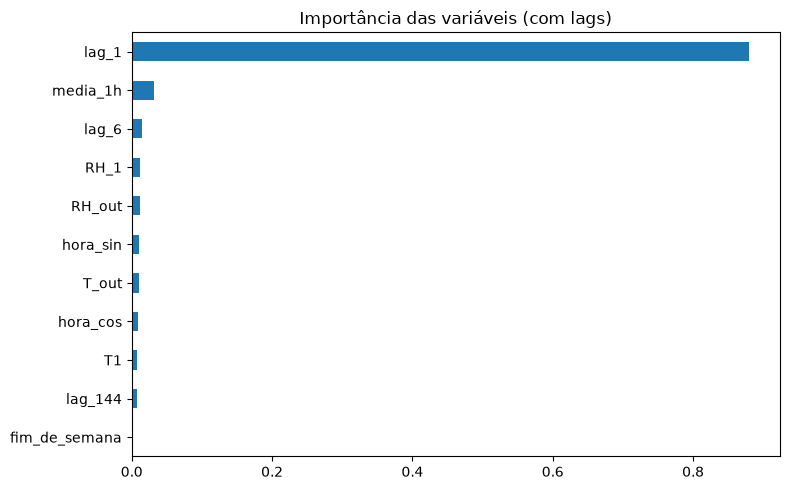

In [14]:
importancias = pd.Series(rf.feature_importances_, index=features).sort_values()
importancias.plot(kind="barh", figsize=(8, 5),
                  title="Importância das variáveis (com lags)")
plt.tight_layout()
plt.savefig("../images/importancias.png", dpi=150)
plt.show()

O `lag_1` domina a importância das variáveis, confirmando que o melhor previsor
do consumo agora é o consumo de poucos minutos atrás.

---
## Conclusão geral

1. **Clima explica pouco do consumo.** Usando só temperatura, umidade e vento,
   nenhum modelo conseguiu superar o baseline.
2. **O histórico recente é o fator mais forte.** Incluir os lags derrubou o erro
   médio pela metade (de ~53 Wh para ~26 Wh).
3. **Modelo simples bastou.** A regressão linear empatou com o Random Forest,
   sendo muito mais rápida e fácil de explicar.
4. **Os picos continuam imprevisíveis**, porque dependem do comportamento das
   pessoas, que não aparece nos dados.

### Limitações

- Dados de uma única casa, por cerca de 4,5 meses. Não generalizam.
- O modelo prevê os próximos 10 minutos, não dias à frente.
- O período de teste cobre uma estação diferente do treino, o que prejudica
  modelos que dependem muito do clima.

### Possíveis próximos passos

- Testar previsão com horizonte maior (1 hora, 1 dia à frente).
- Tratar o problema como classificação: prever se haverá um pico, em vez do valor exato.